# Classification of Plant Leaf Diseases Using Deep Learning
**COMP-671 Final Project (Fall 2026) — Vardhini Talluri**

**Question.** Given a photo of a tomato leaf, can a CNN tell healthy leaves from nine diseases, and which design
choices (architecture, pretraining, augmentation) matter most — and where does it fail?

| Item | Choice |
|---|---|
| Data | PlantVillage tomato subset (10 classes, 18,155 images), leaf-grouped train/val/test split |
| Primary metric | **Macro-F1** on the held-out test set (classes are imbalanced); also accuracy, per-class F1 |
| Baselines | (1) handcrafted colour+texture features + SVM, (2) small CNN trained from scratch |
| Main model | ResNet-18, ImageNet-pretrained (Prince Ch. 10–11) |
| Controlled comparisons | pretrained vs. random init; augmentation on vs. off (Prince Ch. 9) |
| Failure analysis | confusion matrix, hardest errors, Grad-CAM, robustness to blur/noise, leakage check |

The notebook runs top to bottom. Finished runs are cached in `results/`, so re-running only retrains what is missing
(set `FORCE = True` to retrain everything). `SMOKE=1` runs a tiny version for a quick sanity check.

In [1]:
import json, math, os, random, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from torchvision import models
from tqdm import tqdm

plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 6.5, "savefig.dpi": 220})   # figures are sized for a 6.5-inch-wide page

SMOKE = os.environ.get("SMOKE") == "1"      # tiny quick run
FORCE = False                               # True = ignore cached results and retrain everything

ROOT = Path.cwd()
RAW = ROOT / "data" / "raw" / "PlantVillage"
SPLITS = ROOT / "data" / "splits"
RES = ROOT / ("results_smoke" if SMOKE else "results")
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# All hyperparameters live in config.yaml (see that file for what each one means).
import yaml
with open(ROOT / "config.yaml") as f:
    CFG = yaml.safe_load(f)
if SMOKE:                               # quick sanity-check mode: 2 epochs on a tiny subset
    CFG.update(epochs=2, per_class=40)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)


set_seed(CFG["seed"])
print("device:", DEVICE, "| smoke:", SMOKE)
print(CFG)

device: mps | smoke: False
{'seed': 42, 'img': 160, 'epochs': 12, 'batch_size': 64, 'lr': 0.001, 'weight_decay': 0.0001, 'patience': 4, 'val_frac': 0.15, 'per_class': None}


## 1. Data
**Source.** PlantVillage (Hughes & Salathé 2015; Mohanty et al. 2016) as released on Hugging Face
(`mohanty/PlantVillage`, license CC-BY-SA-3.0). We use the *color* images of the 10 tomato classes
(9 diseases + healthy). Each image is a single leaf on a uniform background.

**Split protocol.** PlantVillage has several photos of the same physical leaf, so a random per-image split leaks
near-duplicates between train and test. We split **by leaf** (`leaf_id` from the dataset's `leaf-map.json`):

* **test** = the official PlantVillage test split (tomato only);
* **val** = ~15% of the official train split, chosen with `StratifiedGroupKFold` (grouped by leaf, stratified by class, seed 42);
* **train** = the rest.

The test set is only used for the final evaluation of each finished run; model selection uses validation only.
The split CSVs are committed in `data/splits/`. The next cell downloads the ~2.2 GB archive if needed.

In [2]:
def ensure_images():
    """Download the PlantVillage archive and extract the tomato colour images (skipped if already done)."""
    extracted = RAW / "extracted"
    if (extracted / "raw" / "color").exists() and len(list((extracted / "raw" / "color").glob("Tomato___*/*"))) > 18000:
        return extracted
    from huggingface_hub import hf_hub_download
    for f in ["splits/color_train.txt", "splits/color_test.txt", "leaf_grouping/leaf-map.json", "data.zip"]:
        hf_hub_download("mohanty/PlantVillage", f, repo_type="dataset", local_dir=RAW)
    with zipfile.ZipFile(RAW / "data.zip") as z:
        members = [m for m in z.namelist() if m.startswith("raw/color/") and "/Tomato___" in m and not m.endswith("/")]
        z.extractall(extracted, members=members)
    return extracted


def leaf_id_for(rel, leaf_map):
    """Same leaf_id logic as the dataset's own loader; images without a map entry become their own group."""
    class_name, fname = rel.split("/")[2], rel.split("/")[3]
    ident = fname.replace("_final_masked", "")
    if "___" in ident:
        ident = ident.split("___")[-1]
    ident = ident.split("copy")[0]
    for ext in (".jpg", ".JPG", ".png", ".PNG"):
        ident = ident.replace(ext, "")
    ident = ident.strip()
    opts = leaf_map.get(ident.lower())
    if opts:
        if len(opts) == 1:
            return opts[0]
        for o in opts:
            if class_name in o:
                return o
    return f"fallback_{ident}"


def build_splits():
    leaf_map = json.load(open(RAW / "leaf_grouping" / "leaf-map.json"))
    rows = []
    for part, fname in (("trainval", "color_train.txt"), ("test", "color_test.txt")):
        for line in open(RAW / "splits" / fname):
            rel = line.strip()
            if rel and rel.split("/")[2].startswith("Tomato"):
                rows.append(dict(path=rel, label=rel.split("/")[2], leaf_id=leaf_id_for(rel, leaf_map), part=part))
    df = pd.DataFrame(rows)
    shared = set(df[df.part == "trainval"].leaf_id) & set(df[df.part == "test"].leaf_id)
    df = df[~((df.part == "trainval") & df.leaf_id.isin(shared))]          # drop leaves present in both
    tv = df[df.part == "trainval"].reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=round(1 / CFG["val_frac"]), shuffle=True, random_state=CFG["seed"])
    _, val_idx = next(sgkf.split(tv, tv.label, groups=tv.leaf_id))
    tv["split"] = "train"; tv.loc[val_idx, "split"] = "val"
    te = df[df.part == "test"].assign(split="test")
    out = pd.concat([tv, te], ignore_index=True).drop(columns="part")
    for s in ("train", "val", "test"):
        out[out.split == s][["path", "label", "leaf_id"]].to_csv(SPLITS / f"{s}.csv", index=False)
    return out


IMG_ROOT = ensure_images()
if not all((SPLITS / f"{s}.csv").exists() for s in ("train", "val", "test")):
    build_splits()
meta = pd.concat([pd.read_csv(SPLITS / f"{s}.csv").assign(split=s) for s in ("train", "val", "test")], ignore_index=True)
CLASSES = sorted(meta.label.unique())
SHORT = [c.split("___")[-1].replace("_", " ").replace("Two-spotted spider mite", "").replace("Spider mites ", "Spider mites").strip() for c in CLASSES]
meta["y"] = meta.label.map({c: i for i, c in enumerate(CLASSES)})
meta["fallback"] = meta.leaf_id.str.startswith("fallback_")

# no leaf may appear in two splits
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert not set(meta[meta.split == a].leaf_id) & set(meta[meta.split == b].leaf_id), f"leaf leak {a}/{b}"

if CFG["per_class"]:   # smoke test: small stratified subset
    meta = pd.concat([g.sample(min(len(g), CFG["per_class"]), random_state=0) for _, g in meta.groupby(["split", "label"])], ignore_index=True)

counts = meta.groupby(["label", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
counts.index = SHORT
counts.loc["TOTAL"] = counts.sum()
print(f"leaf groups per split: {meta.groupby('split').leaf_id.nunique().to_dict()} | "
      f"images without leaf-map entry (own group): {meta.fallback.mean():.0%}")
counts

leaf groups per split: {'test': 1921, 'train': 6572, 'val': 1096} | images without leaf-map entry (own group): 37%


split,train,val,test
Bacterial spot,1451,240,436
Early blight,673,112,215
Late blight,1312,219,375
Leaf Mold,668,112,172
Septoria leaf spot,1229,205,337
Spider mites,1160,196,320
Target Spot,957,159,288
Tomato Yellow Leaf Curl Virus,3649,608,1100
Tomato mosaic virus,263,44,66
healthy,1080,179,330


**Reading the table.** The classes are strongly imbalanced (Yellow Leaf Curl Virus is ~30% of the data, Tomato mosaic
virus ~2%), which is why macro-F1 is our primary metric: plain accuracy would reward ignoring the rare classes.

**Known limitation.** The dataset's leaf map covers only part of the images (the fraction printed above has no entry and
is treated as its own group), so a near-duplicate view of the same leaf can still sit on the other side of a split.
The leakage check in Section 4 quantifies this.

**Representation.** All images are decoded once, resized to 160x160, and kept in memory as `uint8`. Pixels are scaled to
[0, 1] and normalised with ImageNet mean/std (needed for the pretrained network, harmless for the others).

(18155, 160, 160, 3) uint8 1.39 GB


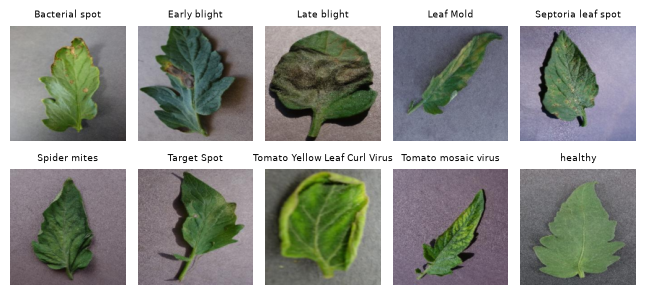

In [3]:
CACHE = ROOT / "data" / "cache"
CACHE.mkdir(exist_ok=True)
cache_file = CACHE / f"tomato_{CFG['img']}{'_smoke' if SMOKE else ''}.npy"
if cache_file.exists():
    X = np.load(cache_file)
else:
    X = np.stack([np.asarray(Image.open(IMG_ROOT / p).convert("RGB").resize((CFG["img"],) * 2, Image.BILINEAR))
                  for p in tqdm(meta.path, desc="decoding images", mininterval=60)])
    np.save(cache_file, X)
idx = {s: np.where(meta.split == s)[0] for s in ("train", "val", "test")}
Y = meta.y.values
print(X.shape, X.dtype, f"{X.nbytes / 1e9:.2f} GB")

fig, axes = plt.subplots(2, 5, figsize=(6.5, 3.1))
for i, ax in enumerate(axes.ravel()):
    j = np.where((Y == i) & (meta.split == "train").values)[0][0]
    ax.imshow(X[j]); ax.set_title(SHORT[i], fontsize=6.5); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "fig1_examples.png", dpi=220); plt.show()

*Figure 1. One training example per class. All photos are single leaves on a plain background, which is much easier
than real field images (see the limitations).*

## 2. Models and training
* **Baseline 1 — handcrafted features + SVM** (non-deep): HSV colour histograms, uniform LBP texture histogram and RGB
  mean/std, fed to an RBF SVM. This tells us how much of the task is solvable without learning features.
* **Baseline 2 — small CNN from scratch** (Ch. 10): 4 x (conv–BatchNorm–ReLU–maxpool), global average pooling, dropout,
  linear head (~0.4 M parameters).
* **Main model — ResNet-18** (Ch. 11): residual blocks and batch norm make a deeper net trainable; we start from ImageNet
  weights and replace the head with a 10-way linear layer.

**Loss / optimiser.** Cross-entropy (maximum likelihood for a categorical output, Ch. 5), Adam with cosine learning-rate
decay, batch 64, early stopping on validation macro-F1. **Augmentation** (Ch. 9), applied on the GPU per sample:
random rotation ±20°, zoom up to 1.25x, translation ±10%, horizontal/vertical flips, brightness and contrast jitter.
Controlled comparisons change exactly one factor and keep seed, data, optimiser and epochs identical.

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def to_float(xb):                      # uint8 NHWC (cpu) -> float NCHW in [0,1] on device
    return torch.from_numpy(xb).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0


def normalize(x):
    return (x - MEAN) / STD


def augment(x):
    """Per-sample random affine (rotation, zoom, shift, flips) + brightness/contrast jitter on a [0,1] batch."""
    B, d = x.size(0), x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(20)
    s = 0.8 + 0.2 * torch.rand(B, device=d)
    fx = torch.where(torch.rand(B, device=d) < 0.5, -1.0, 1.0)
    fy = torch.where(torch.rand(B, device=d) < 0.5, -1.0, 1.0)
    c, sn = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=d)
    theta[:, 0, 0], theta[:, 0, 1] = s * c * fx, -s * sn * fy
    theta[:, 1, 0], theta[:, 1, 1] = s * sn * fx, s * c * fy
    theta[:, :, 2] = (torch.rand(B, 2, device=d) * 2 - 1) * 0.1
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
    b = 0.75 + 0.5 * torch.rand(B, 1, 1, 1, device=d)
    ct = 0.75 + 0.5 * torch.rand(B, 1, 1, 1, device=d)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * ct + m).mul(b).clamp(0, 1)


class SmallCNN(nn.Module):
    def __init__(self, n_classes, widths=(32, 64, 128, 256), dropout=0.3):
        super().__init__()
        layers, c = [], 3
        for w in widths:
            layers += [nn.Conv2d(c, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c = w
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_resnet18(n_classes, pretrained=True):
    net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    net.fc = nn.Linear(net.fc.in_features, n_classes)
    return net


def metrics(y, p):
    labels = list(range(len(CLASSES)))
    return dict(accuracy=float(accuracy_score(y, p)),
                macro_f1=float(f1_score(y, p, average="macro", labels=labels, zero_division=0)),
                per_class_f1=f1_score(y, p, average=None, labels=labels, zero_division=0).tolist(),
                confusion=confusion_matrix(y, p, labels=labels).tolist())


@torch.no_grad()
def predict_proba(model, Xs, bs=256, transform=None):
    model.eval(); out = []
    for i in range(0, len(Xs), bs):
        x = to_float(Xs[i:i + bs])
        if transform is not None:
            x = transform(x)
        out.append(model(normalize(x)).softmax(1).cpu().numpy())
    return np.concatenate(out)


def train_model(name, build, augmentation):
    """Train, pick the best epoch on validation macro-F1, evaluate once on test, cache everything under results/."""
    cache = RES / f"{name}.json"
    if cache.exists() and (RES / f"{name}.pt").exists() and not FORCE:      # cached only if the weights are there too
        print(f"[{name}] loaded cached results")
        return json.load(open(cache))
    set_seed(CFG["seed"])
    model = build().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG["epochs"])
    tr, va = idx["train"], idx["val"]
    best, best_state, bad, hist = -1.0, None, 0, []
    for ep in range(1, CFG["epochs"] + 1):
        t0 = time.time(); model.train()
        perm = np.random.permutation(tr); tot, correct = 0.0, 0
        for i in range(0, len(perm), CFG["batch_size"]):
            b = np.sort(perm[i:i + CFG["batch_size"]])
            x = to_float(X[b]); y = torch.from_numpy(Y[b]).to(DEVICE)
            if augmentation:
                x = augment(x)
            logits = model(normalize(x)); loss = F.cross_entropy(logits, y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item() * len(b); correct += (logits.argmax(1) == y).sum().item()
        sched.step()
        pv = predict_proba(model, X[va]); vm = metrics(Y[va], pv.argmax(1))
        vloss = float(-np.log(pv[np.arange(len(va)), Y[va]] + 1e-9).mean())
        hist.append(dict(epoch=ep, train_loss=tot / len(tr), train_acc=correct / len(tr), val_loss=vloss,
                         val_acc=vm["accuracy"], val_macro_f1=vm["macro_f1"], sec=time.time() - t0))
        print(f"[{name}] epoch {ep:02d} train_loss={tot / len(tr):.4f} val_loss={vloss:.4f} "
              f"val_acc={vm['accuracy']:.4f} val_macro_f1={vm['macro_f1']:.4f} ({time.time() - t0:.0f}s)")
        if vm["macro_f1"] > best:
            best, bad = vm["macro_f1"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            best_ep = ep
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"[{name}] early stop at epoch {ep}"); break
    model.load_state_dict(best_state)
    te = idx["test"]; pt = predict_proba(model, X[te])
    res = dict(name=name, best_epoch=best_ep, val_macro_f1=best, history=hist, test=metrics(Y[te], pt.argmax(1)),
               n_params=sum(p.numel() for p in model.parameters()), train_minutes=sum(h["sec"] for h in hist) / 60)
    torch.save(best_state, RES / f"{name}.pt")
    np.save(RES / f"{name}_test_probs.npy", pt.astype(np.float16))
    json.dump(res, open(cache, "w"))
    print(f"[{name}] TEST acc={res['test']['accuracy']:.4f} macro_f1={res['test']['macro_f1']:.4f}")
    return res


def load_model(name):
    net = make_resnet18(len(CLASSES), False) if name.startswith("resnet18") else SmallCNN(len(CLASSES))
    net.load_state_dict(torch.load(RES / f"{name}.pt", map_location=DEVICE)); return net.to(DEVICE).eval()

### Baseline 1: handcrafted features + SVM

In [5]:
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


def handcrafted(imgs):
    out = []
    for im in tqdm(imgs, desc="features", leave=False, mininterval=60):
        hsv = rgb2hsv(im)
        h = [np.histogram(hsv[..., c], bins=24, range=(0, 1))[0] for c in range(3)]
        lbp = local_binary_pattern((rgb2gray(im) * 255).astype(np.uint8), 8, 1, "uniform")
        h.append(np.histogram(lbp, bins=10, range=(0, 10))[0])
        f = np.concatenate([hh / hh.sum() for hh in h] + [im.reshape(-1, 3).mean(0) / 255, im.reshape(-1, 3).std(0) / 255])
        out.append(f)
    return np.array(out, dtype=np.float32)


svm_cache = RES / "svm_handcrafted.json"
svm_preds_file = RES / "svm_handcrafted_test_preds.npy"
if svm_cache.exists() and svm_preds_file.exists() and not FORCE:
    svm_res = json.load(open(svm_cache)); print("[svm] loaded cached results")
else:
    t0 = time.time()
    feats = {s: handcrafted(X[idx[s]]) for s in idx}
    sc = StandardScaler().fit(feats["train"])
    best = None
    for C in (1, 10, 100):                       # tune C on validation only
        clf = SVC(C=C, kernel="rbf", gamma="scale", class_weight="balanced").fit(sc.transform(feats["train"]), Y[idx["train"]])
        f1 = f1_score(Y[idx["val"]], clf.predict(sc.transform(feats["val"])), average="macro")
        print(f"[svm] C={C}: val macro-F1={f1:.4f}")
        if best is None or f1 > best[0]:
            best = (f1, C, clf)
    pt = best[2].predict(sc.transform(feats["test"]))
    np.save(svm_preds_file, pt)
    svm_res = dict(name="svm_handcrafted", val_macro_f1=best[0], best_C=best[1], test=metrics(Y[idx["test"]], pt),
                   n_params=None, train_minutes=(time.time() - t0) / 60)
    json.dump(svm_res, open(svm_cache, "w"))
print(f"[svm] TEST acc={svm_res['test']['accuracy']:.4f} macro_f1={svm_res['test']['macro_f1']:.4f}")

[svm] loaded cached results
[svm] TEST acc=0.9651 macro_f1=0.9593


### Deep models and the controlled comparisons
| Run | Model | Init | Augmentation | Purpose |
|---|---|---|---|---|
| `small_cnn_aug` | Small CNN | random | on | deep baseline |
| `resnet18_scratch_aug` | ResNet-18 | random | on | **ablation A:** isolates the effect of pretraining (vs. main) |
| `resnet18_pretrained_noaug` | ResNet-18 | ImageNet | off | **ablation B:** isolates the effect of augmentation (vs. main) |
| `resnet18_pretrained_aug` | ResNet-18 | ImageNet | on | **main model** |

In [6]:
RUNS = {
    "small_cnn_aug": (lambda: SmallCNN(len(CLASSES)), True),
    "resnet18_scratch_aug": (lambda: make_resnet18(len(CLASSES), pretrained=False), True),
    "resnet18_pretrained_noaug": (lambda: make_resnet18(len(CLASSES), pretrained=True), False),
    "resnet18_pretrained_aug": (lambda: make_resnet18(len(CLASSES), pretrained=True), True),
}
results = {"svm_handcrafted": svm_res}
for name, (build, aug) in RUNS.items():
    results[name] = train_model(name, build, aug)

[small_cnn_aug] loaded cached results
[resnet18_scratch_aug] loaded cached results
[resnet18_pretrained_noaug] loaded cached results
[resnet18_pretrained_aug] loaded cached results


## 3. Results

In [7]:
LABEL = {"svm_handcrafted": "Handcrafted features + SVM", "small_cnn_aug": "Small CNN (scratch, aug)",
         "resnet18_scratch_aug": "ResNet-18 (scratch, aug)", "resnet18_pretrained_noaug": "ResNet-18 (pretrained, no aug)",
         "resnet18_pretrained_aug": "ResNet-18 (pretrained, aug) — main"}
table = pd.DataFrame([{
    "Model": LABEL[k], "Params (M)": (r["n_params"] / 1e6) if r.get("n_params") else np.nan,
    "Best epoch": r.get("best_epoch", np.nan), "Val macro-F1": r["val_macro_f1"],
    "Test accuracy": r["test"]["accuracy"], "Test macro-F1": r["test"]["macro_f1"],
    "Train min": r["train_minutes"]} for k, r in results.items()]).set_index("Model")
table.round(4).to_csv(RES / "results_table.csv")
table.round(4)

,Params (M),Best epoch,Val macro-F1,Test accuracy,Test macro-F1,Train min
Model,,,,,,
Handcrafted features + SVM,NaN,NaN,0.9655,0.9651,0.9593,1.1239
"Small CNN (scratch, aug)",0.3915,11.0,0.8443,0.8667,0.8349,7.8825
"ResNet-18 (scratch, aug)",11.1816,9.0,0.9547,0.9508,0.9403,13.5745
"ResNet-18 (pretrained, no aug)",11.1816,9.0,0.9902,0.9890,0.9852,29.0335
"ResNet-18 (pretrained, aug) — main",11.1816,11.0,0.9689,0.9813,0.9797,14.9839


*Table 1. Validation and held-out test performance of every model (one run each, seed 42). Test numbers are from the
checkpoint with the best validation macro-F1.*

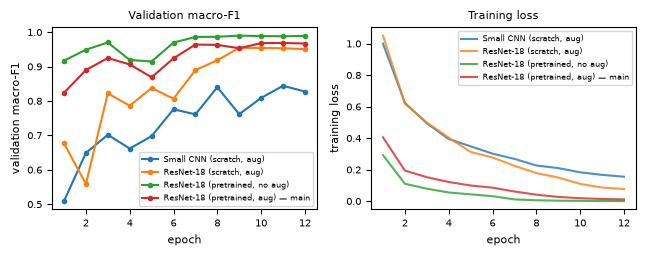

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(6.5, 2.6))
for k in RUNS:
    h = pd.DataFrame(results[k]["history"])
    ax[0].plot(h.epoch, h.val_macro_f1, marker="o", ms=3, label=LABEL[k])
    ax[1].plot(h.epoch, h.train_loss, label=LABEL[k], alpha=.8)
ax[0].set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1"); ax[0].legend(fontsize=5.5)
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss"); ax[1].legend(fontsize=5.5)
plt.tight_layout(); plt.savefig(FIG / "fig2_curves.png", dpi=220); plt.show()

*Figure 2. Validation macro-F1 (left) and training loss (right) per epoch. The pretrained network starts far ahead and the
from-scratch models need many more epochs to catch up.*

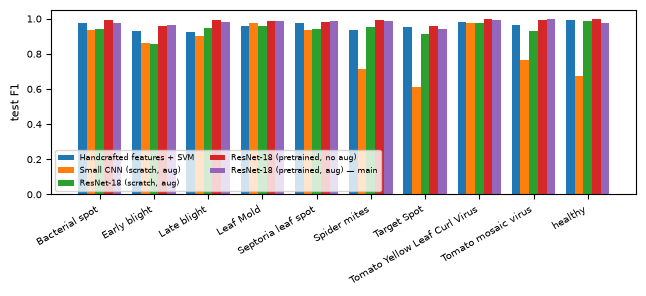

In [9]:
labs = [LABEL[k] for k in results]
f1s = np.array([results[k]["test"]["per_class_f1"] for k in results])
fig, ax = plt.subplots(figsize=(6.5, 3.0)); w = 0.8 / len(labs)
for i, l in enumerate(labs):
    ax.bar(np.arange(len(SHORT)) + i * w, f1s[i], w, label=l)
ax.set_xticks(np.arange(len(SHORT)) + 0.4 - w / 2, SHORT, rotation=30, ha="right"); ax.set_ylabel("test F1"); ax.set_ylim(0, 1.05)
ax.legend(fontsize=5.5, ncol=2, loc="lower left"); plt.tight_layout(); plt.savefig(FIG / "fig3_per_class_f1.png", dpi=220); plt.show()

*Figure 3. Per-class test F1 for every model. The rare and visually similar classes separate the models far more than the easy ones.*

## 4. Failure analysis
We analyse the main model (`resnet18_pretrained_aug`): where it confuses classes, which errors are most confident,
and — with Grad-CAM — whether it looks at the lesion or at something irrelevant.

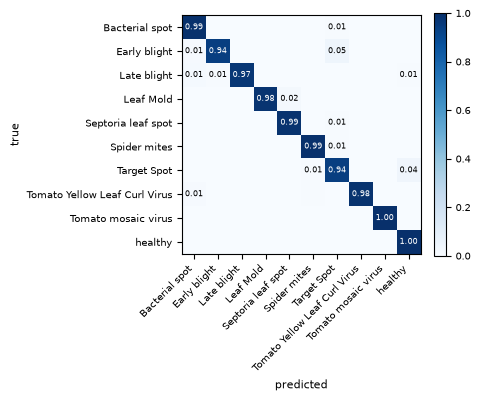

,true class,predicted as,count,share of true class
0,Target Spot,healthy,12,0.042
1,Early blight,Target Spot,10,0.047
2,Tomato Yellow Leaf Curl Virus,Bacterial spot,9,0.008
3,Late blight,Bacterial spot,5,0.013
4,Tomato Yellow Leaf Curl Virus,Spider mites,5,0.005
5,Bacterial spot,Target Spot,3,0.007


In [10]:
MAIN = "resnet18_pretrained_aug"
te = idx["test"]; yt = Y[te]
probs = np.load(RES / f"{MAIN}_test_probs.npy").astype(np.float32); yp = probs.argmax(1)
cm = np.array(results[MAIN]["test"]["confusion"])
fig, ax = plt.subplots(figsize=(4.7, 4.1))
cmn = cm / cm.sum(1, keepdims=True)
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(SHORT)), SHORT, rotation=45, ha="right"); ax.set_yticks(range(len(SHORT)), SHORT)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(len(SHORT)):
    for j in range(len(SHORT)):
        if cmn[i, j] > 0.005:
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=5.5, color="white" if cmn[i, j] > .5 else "black")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(FIG / "fig4_confusion.png", dpi=220); plt.show()
pairs = [(SHORT[i], SHORT[j], int(cm[i, j]), cm[i, j] / cm[i].sum()) for i in range(len(SHORT)) for j in range(len(SHORT)) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(pairs, key=lambda r: -r[2])[:6], columns=["true class", "predicted as", "count", "share of true class"]).round(3)

*Figure 4. Row-normalised confusion matrix of the main model on the test set; the table lists the most frequent confusions.*

In [11]:
# Direction of the errors: a missed disease (diseased predicted healthy) is costlier than a false alarm.
H = CLASSES.index("Tomato___healthy"); dis = [i for i in range(len(CLASSES)) if i != H]
for name in ("resnet18_pretrained_aug", "resnet18_pretrained_noaug"):
    c_ = np.array(results[name]["test"]["confusion"])
    print(f"{LABEL[name]}: diseased->healthy = {c_[dis, H].sum()}, healthy->diseased = {c_[H, dis].sum()}, total errors = {c_.sum() - np.trace(c_)}")

ResNet-18 (pretrained, aug) — main: diseased->healthy = 16, healthy->diseased = 0, total errors = 68
ResNet-18 (pretrained, no aug): diseased->healthy = 0, healthy->diseased = 2, total errors = 40


*The augmented model's errors lean toward calling diseased leaves healthy; the no-augmentation model's errors do not.*

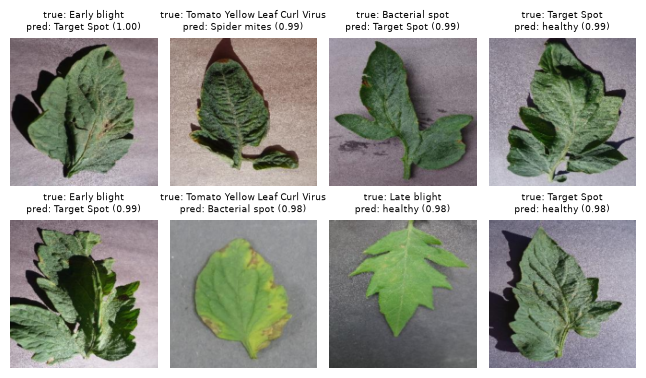

68 / 3639 test errors; mean confidence on errors 0.77 vs. correct 0.99


In [12]:
wrong = np.where(yp != yt)[0]
conf = probs.max(1)
worst = wrong[np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(2, 4, figsize=(6.5, 3.9))
for ax, k in zip(axes.ravel(), worst):
    ax.imshow(X[te[k]]); ax.axis("off")
    ax.set_title(f"true: {SHORT[yt[k]]}\npred: {SHORT[yp[k]]} ({conf[k]:.2f})", fontsize=6.5)
plt.tight_layout(); plt.savefig(FIG / "fig5_worst_errors.png", dpi=220); plt.show()
print(f"{len(wrong)} / {len(te)} test errors; mean confidence on errors {conf[wrong].mean():.2f} vs. correct {conf[yp == yt].mean():.2f}")

*Figure 5. The eight most confident mistakes of the main model, with true label, prediction and confidence.*

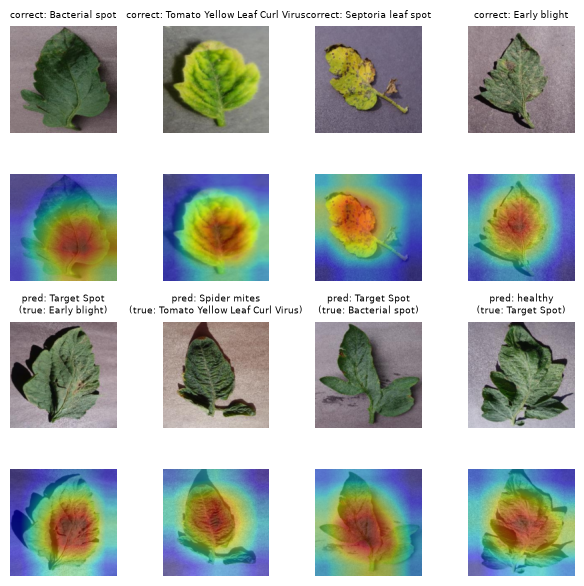

In [13]:
def gradcam(model, x, target):
    """Grad-CAM on the last residual stage of ResNet-18. x: normalised 1x3xHxW."""
    store = {}
    def fwd(m, i, o):
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd)
    model.zero_grad(); out = model(x); out[0, target].backward(); h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy()


net = load_model(MAIN)
rng = np.random.RandomState(0)
right = np.where(yp == yt)[0]
picks = list(rng.choice(right, 4, replace=False)) + list(worst[:4])
fig, axes = plt.subplots(4, 4, figsize=(6.3, 5.9))
for n, k in enumerate(picks):
    r, col = (0 if n < 4 else 2), n % 4          # rows 0-1: correct predictions, rows 2-3: confident errors
    x = normalize(to_float(X[te[k]][None]))
    cam = gradcam(net, x, int(yp[k]))
    title = f"correct: {SHORT[yp[k]]}" if yp[k] == yt[k] else f"pred: {SHORT[yp[k]]}\n(true: {SHORT[yt[k]]})"
    axes[r, col].imshow(X[te[k]]); axes[r, col].axis("off"); axes[r, col].set_title(title, fontsize=6.5)
    axes[r + 1, col].imshow(X[te[k]]); axes[r + 1, col].imshow(cam, cmap="jet", alpha=0.45); axes[r + 1, col].axis("off")
plt.tight_layout(); plt.savefig(FIG / "fig6_gradcam.png", dpi=220); plt.show()

*Figure 6. Grad-CAM for the predicted class on four random correct predictions (top two rows) and four of the confident errors from Figure 5 (bottom two rows). Red = regions that drive the prediction.*

### Robustness to image degradation
Real photos are blurry and noisy; PlantVillage's are not. We degrade the **test** images (never used for training) and
compare the pretrained model with and without augmentation, and the small CNN.

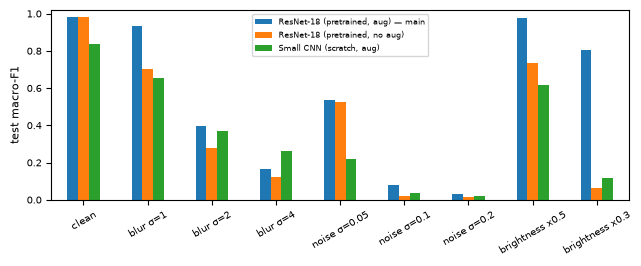

,"ResNet-18 (pretrained, aug) — main","ResNet-18 (pretrained, no aug)","Small CNN (scratch, aug)"
clean,0.980,0.985,0.835
blur σ=1,0.935,0.701,0.652
blur σ=2,0.398,0.280,0.371
blur σ=4,0.164,0.122,0.263
noise σ=0.05,0.539,0.524,0.217
noise σ=0.1,0.082,0.018,0.039
noise σ=0.2,0.032,0.017,0.019
brightness x0.5,0.975,0.734,0.617
brightness x0.3,0.807,0.066,0.119


In [14]:
import torchvision.transforms.functional as TF
def blur(s):  return (lambda x: TF.gaussian_blur(x, kernel_size=2 * int(3 * s) + 1, sigma=s)) if s > 0 else (lambda x: x)
def noise(s): return lambda x: (x + s * torch.randn_like(x)).clamp(0, 1)
def dark(f):  return lambda x: (x * f).clamp(0, 1)
conds = [("clean", lambda x: x)] + [(f"blur σ={s}", blur(s)) for s in (1, 2, 4)] + \
        [(f"noise σ={s}", noise(s)) for s in (0.05, 0.1, 0.2)] + [(f"brightness x{f}", dark(f)) for f in (0.5, 0.3)]
rob = {}
for name in ("resnet18_pretrained_aug", "resnet18_pretrained_noaug", "small_cnn_aug"):
    m = load_model(name)
    scores = []
    for _, t in conds:
        set_seed(CFG["seed"])          # same noise draw for every model and every re-run
        scores.append(f1_score(yt, predict_proba(m, X[te], transform=t).argmax(1), average="macro"))
    rob[LABEL[name]] = scores
rob_df = pd.DataFrame(rob, index=[c for c, _ in conds]).round(3)
rob_df.to_csv(RES / "robustness.csv")
ax = rob_df.plot.bar(figsize=(6.5, 2.7), rot=30); ax.set_ylabel("test macro-F1"); ax.set_ylim(0, 1.02); ax.legend(fontsize=6)
plt.tight_layout(); plt.savefig(FIG / "fig7_robustness.png", dpi=220); plt.show()
rob_df

*Figure 7 / Table 2. Test macro-F1 under blur, noise and darkening. Augmentation was trained with brightness/contrast jitter
but never with blur or noise.*

### Leakage check
The leaf map does not cover every image, so we test directly how close test images are to training images. For each test
image we find the nearest training image (L2 distance on 32x32 grayscale thumbnails). Test images whose leaf *is* grouped by
the leaf map are guaranteed to be on one side of the split; the others are not.

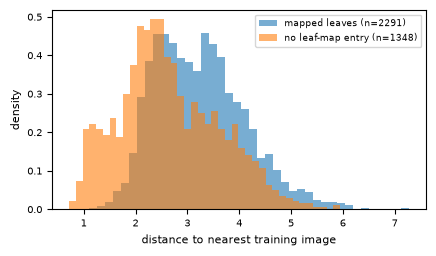

median NN distance: mapped 3.17 vs. unmapped 2.50
main-model test accuracy: mapped leaves 0.9847 vs. unmapped 0.9755


In [15]:
def thumbs(a):
    return torch.nn.functional.adaptive_avg_pool2d(to_float(a).mean(1, keepdim=True), 32).flatten(1)
Ttr = torch.cat([thumbs(X[idx["train"][i:i + 1000]]) for i in range(0, len(idx["train"]), 1000)])
Tte = torch.cat([thumbs(X[te[i:i + 1000]]) for i in range(0, len(te), 1000)])
nn_dist = torch.cdist(Tte, Ttr).min(1).values.cpu().numpy()
fb = meta.fallback.values[te]
fig, ax = plt.subplots(figsize=(4.4, 2.6))
ax.hist(nn_dist[~fb], bins=40, alpha=.6, label=f"mapped leaves (n={int((~fb).sum())})", density=True)
ax.hist(nn_dist[fb], bins=40, alpha=.6, label=f"no leaf-map entry (n={int(fb.sum())})", density=True)
ax.set(xlabel="distance to nearest training image", ylabel="density"); ax.legend(fontsize=6.5)
plt.tight_layout(); plt.savefig(FIG / "fig8_leakage.png", dpi=220); plt.show()
acc_fb = (yp[fb] == yt[fb]).mean(); acc_map = (yp[~fb] == yt[~fb]).mean()
print(f"median NN distance: mapped {np.median(nn_dist[~fb]):.2f} vs. unmapped {np.median(nn_dist[fb]):.2f}")
print(f"main-model test accuracy: mapped leaves {acc_map:.4f} vs. unmapped {acc_fb:.4f}")

*Figure 8. Distance from each test image to its nearest training image, split by whether the image's leaf is covered by the
leaf map. If unmapped images were systematically closer to training images, near-duplicate leakage would be likely.*

### Statistical uncertainty
Every model was trained once (seed 42), so we cannot measure training-run variance. What we *can* measure is test-set sampling uncertainty.
We bootstrap the test set **by leaf** (resampling whole leaf groups, so near-duplicate views of one leaf stay together) 1,000 times and report
95% percentile intervals for macro-F1 and for the *paired* difference between two models on the same resamples.

In [16]:
yt = Y[idx["test"]]
test_meta = meta[meta.split == "test"].reset_index(drop=True)
_, inv = np.unique(test_meta.leaf_id.values, return_inverse=True)
members = [np.where(inv == g)[0] for g in range(inv.max() + 1)]
PRED = {k: np.load(RES / f"{k}_test_probs.npy").astype(np.float32).argmax(1) for k in RUNS}
PRED["svm_handcrafted"] = np.load(RES / "svm_handcrafted_test_preds.npy")
assert abs(f1_score(yt, PRED["svm_handcrafted"], average="macro") - results["svm_handcrafted"]["test"]["macro_f1"]) < 1e-9
rng, B = np.random.RandomState(0), 1000
boot = {k: np.zeros(B) for k in PRED}
for b in range(B):
    pick = rng.randint(0, len(members), len(members))
    ii = np.concatenate([members[g] for g in pick])
    for k, p in PRED.items():
        boot[k][b] = f1_score(yt[ii], p[ii], average="macro", labels=list(range(len(CLASSES))), zero_division=0)
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
rows = [dict(model=LABEL[k], macro_f1=results[k]["test"]["macro_f1"], ci_low=ci(boot[k])[0], ci_high=ci(boot[k])[1]) for k in PRED]
pairs = [("resnet18_pretrained_aug", "resnet18_pretrained_noaug", "pretrained+aug minus pretrained, no aug (ablation B)"),
         ("resnet18_pretrained_aug", "resnet18_scratch_aug", "pretrained minus scratch, both aug (ablation A)"),
         ("resnet18_pretrained_aug", "svm_handcrafted", "main ResNet-18 minus SVM"),
         ("resnet18_scratch_aug", "svm_handcrafted", "ResNet-18 scratch minus SVM"),
         ("resnet18_pretrained_noaug", "resnet18_pretrained_aug", "no aug minus aug (same as first, sign flipped)")]
drows = []
for a, b_, desc in pairs[:4]:
    d = boot[a] - boot[b_]
    drows.append(dict(comparison=desc, diff=results[a]["test"]["macro_f1"] - results[b_]["test"]["macro_f1"],
                      ci_low=ci(d)[0], ci_high=ci(d)[1], frac_boot_positive=float((d > 0).mean())))
ci_df, diff_df = pd.DataFrame(rows).round(4), pd.DataFrame(drows).round(4)
ci_df.to_csv(RES / "bootstrap_ci.csv", index=False); diff_df.to_csv(RES / "bootstrap_paired_diffs.csv", index=False)
print(ci_df.to_string(index=False)); print(); print(diff_df.to_string(index=False))

                             model  macro_f1  ci_low  ci_high
          Small CNN (scratch, aug)    0.8349  0.8148   0.8522
          ResNet-18 (scratch, aug)    0.9403  0.9267   0.9520
    ResNet-18 (pretrained, no aug)    0.9852  0.9797   0.9903
ResNet-18 (pretrained, aug) — main    0.9797  0.9730   0.9857
        Handcrafted features + SVM    0.9593  0.9488   0.9691

                                          comparison    diff  ci_low  ci_high  frac_boot_positive
pretrained+aug minus pretrained, no aug (ablation B) -0.0055 -0.0121   0.0007               0.041
     pretrained minus scratch, both aug (ablation A)  0.0393  0.0282   0.0529               1.000
                            main ResNet-18 minus SVM  0.0203  0.0093   0.0318               1.000
                         ResNet-18 scratch minus SVM -0.0190 -0.0342  -0.0055               0.006


*Table 3. Test macro-F1 with 95% leaf-level bootstrap intervals (top) and paired differences between models (bottom).
These intervals reflect test-set sampling only, not variation across training seeds.*

## 5. Discussion, limitations and ethics

**What the results show (single training run per model, seed 42; the bootstrap intervals in Table 3 cover test-set sampling only, not seed-to-seed variation).**
* **Pretraining matters most.** With augmentation fixed, ImageNet initialisation raises test macro-F1 from 0.940 to 0.980 (ablation A).
  The same ResNet-18 trained from scratch is worse than the handcrafted SVM (0.959), so on this small, easy dataset a good
  initialisation is worth more than a bigger architecture.
* **The non-deep baseline is strong.** Colour and texture features alone reach 0.959 macro-F1, because lab-style images are separable by
  lesion colour. The small from-scratch CNN (0.835) is clearly worse than the SVM; the deep models only pay off once pretrained.
* **Augmentation did not help clean accuracy, but it helps robustness (ablation B).** Without augmentation the pretrained model scores slightly
  higher on clean data (test macro-F1 0.985 vs 0.980; validation 0.990 vs 0.969). The paired bootstrap difference is -0.006 with a 95% interval of
  [-0.012, +0.001] (Table 3), so on this test set the two are not distinguishable. We designated the augmented model as "main" before seeing
  results; by validation macro-F1 alone the no-augmentation model would have been selected, and we say so. Under degradation the picture reverses:
  at blur sigma=1 macro-F1 is 0.935 (aug) vs 0.701 (no aug), and with 50% darkening 0.975 vs 0.734 (Table 2). Augmentation buys robustness to the
  shifts it simulates.
* **Neither model is robust to noise or strong blur.** Gaussian noise with sigma=0.1 or blur with sigma>=2 drops the main model to near chance or
  far below its clean score, even though augmentation never included noise. Augmentation only protects against the corruptions it covers.

**Failure analysis.** The main model makes 68 errors on 3,639 test images. The most frequent confusions are Target Spot -> healthy (12 of 288),
Early blight -> Target Spot (10 of 215) and Yellow Leaf Curl Virus -> Bacterial spot (9). The first is the most worrying: a diseased leaf called
healthy. Of the 68 errors, 16 call a diseased leaf healthy and none call a healthy leaf diseased; the no-augmentation model, with 40 errors, has none of the first kind and 2 of the second, so the choice between the two is not only about accuracy. The errors are *confident* (mean confidence 0.77 on errors vs. 0.99 on correct predictions), so confidence alone cannot flag them reliably.
The worst errors (Fig. 5) are leaves with faint or small lesions, curled or shadowed leaves, and classes that look alike (Target Spot vs. Early blight).
Grad-CAM (Fig. 6) shows attention concentrated on the central leaf area for correct *and* wrong predictions; the maps are coarse (5x5 final
feature map at 160 px), so they confirm the model looks at the leaf and not the background but do not prove it localises individual lesions.

**Limitations.**
1. *Lab images.* Every photo is a single leaf on a plain background. Scores here will overstate performance on real field photos, which we did not test.
2. *Incomplete leaf grouping.* About 37% of images have no leaf-map entry and are treated as their own group, so near-duplicate views of one leaf could
   cross the split. Unmapped test images are indeed closer to training images (median distance 2.50 vs 3.17, Fig. 8), which is consistent with some
   leakage, but the model is not more accurate on them (97.6% vs 98.5%); the groups also differ in class mix, so this check is suggestive, not conclusive.
3. *One seed, one crop, fixed 160 px resolution, 12 epochs.* No confidence intervals; small gaps between models should not be over-read.
4. *Class imbalance.* Rare classes (Tomato mosaic virus, 66 test images) have noisy per-class F1.

**Ethics and responsible use.** A leaf-disease classifier is a decision aid, not a diagnosis. (i) *Over-trust:* confident wrong answers (above) could
lead a grower to skip treatment of a diseased plant (Target Spot called healthy) or to spray unnecessarily, with cost and environmental consequences;
any deployment should show uncertainty and recommend expert confirmation. (ii) *Dataset bias:* one crop, controlled lighting and backgrounds, and
disease appearances from a limited set of conditions, so it may fail for other varieties, regions, growth stages or phone cameras, which can
disadvantage smallholders whose conditions differ most from the lab. (iii) *Misuse and scope:* it covers only 10 tomato classes and will confidently
mislabel anything else (other crops, nutrient deficiency, pesticide damage). (iv) *Compute:* all experiments ran on a single laptop in about
1.2 hours of training (about 1.5 hours including analysis), a small footprint, but the cost of repeated tuning should be reported. (v) *Licensing:* the data is CC-BY-SA-3.0 and is not redistributed here.
